# **i210547 Haider Rizvi**

In [1]:
# Core
import pandas as pd
import numpy as np
import re
import string
import random

# Visualization / EDA
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing / NLP
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Ensure nltk data is downloaded
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

# Google Colab file upload
from google.colab import files

# Optional: warnings filter
import warnings
warnings.filterwarnings("ignore")

# Optional: For reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


# **Task 1: Data Preprocessing & EDA**

***• Load your finance dataset***

In [2]:
from google.colab import drive
drive.mount('/content/drive')
dataset_path = "/content/drive/MyDrive/dataset/FinancialPhraseBank-v1.0/Sentences_75Agree.txt"



Mounted at /content/drive


In [3]:
data = pd.read_csv(dataset_path, sep='@', header=None, names=['sentence', 'sentiment'], engine='python', encoding='latin1')
data.head()

,sentence,sentiment
0,"According to Gran , the company has no plans t...",neutral
1,With the new production plant the company woul...,positive
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,"In the third quarter of 2010 , net sales incre...",positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive


***• Clean and preprocess text (lowercase, punctuation removal, tokenization, stopword
removal)***

In [4]:
# Initialize stopwords list and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [5]:
# Define preprocessing function
def preprocess_text(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize
    tokens = nltk.word_tokenize(text)

    # 4. Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # 5. Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Return cleaned text as a string
    return ' '.join(tokens)

In [6]:
#  Apply preprocessing to the 'sentence' column
data['cleaned_sentence'] = data['sentence'].apply(preprocess_text)

# Inspect the first 5 cleaned sentences
data[['sentence', 'cleaned_sentence', 'sentiment']].head()

,sentence,cleaned_sentence,sentiment
0,"According to Gran , the company has no plans t...",according gran company plan move production ru...,neutral
1,With the new production plant the company woul...,new production plant company would increase ca...,positive
2,"For the last quarter of 2010 , Componenta 's n...",last quarter componenta net sale doubled eurm ...,positive
3,"In the third quarter of 2010 , net sales incre...",third quarter net sale increased eur mn operat...,positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,operating profit rose eur mn eur mn correspond...,positive


cleaned_sentence column now contains lowercased, tokenized, stopword-removed, lemmatized sentences, exactly what is needed for both LDA topic modeling and sentiment analysis.

***• Provide basic dataset insights (class balance, sample sentences, length distribution)***

Class distribution:
 sentiment
neutral     2146
positive     887
negative     420
Name: count, dtype: int64


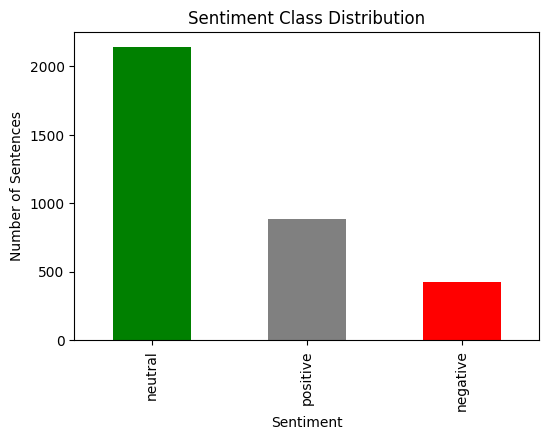

In [7]:
# Class balance
class_counts = data['sentiment'].value_counts()
print("Class distribution:\n", class_counts)

# Plot class balance
plt.figure(figsize=(6,4))
class_counts.plot(kind='bar', color=['green', 'gray', 'red'])
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Sentences')
plt.show()


Class Balance Insights

Neutral: 2,146 sentences → ~62% of dataset

Positive: 887 sentences → ~26% of dataset

Negative: 420 sentences → ~12% of dataset

Implications:

The dataset is heavily skewed toward neutral sentences.

For sentiment modeling, this imbalance may affect metrics like accuracy, so later we might consider:

Using class-weighted loss in training

Oversampling minority classes or downsampling neutral class (if needed)

For LDA topic modeling, class balance does not matter — we can use all sentences.

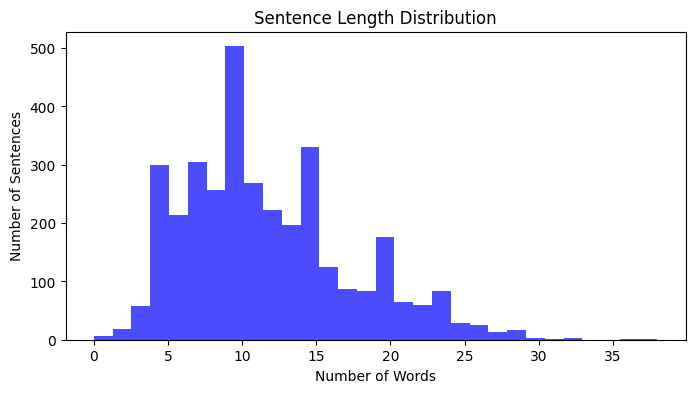

In [8]:
# Sentence length distribution
data['sentence_length'] = data['cleaned_sentence'].apply(lambda x: len(x.split()))
plt.figure(figsize=(8,4))
plt.hist(data['sentence_length'], bins=30, color='blue', alpha=0.7)
plt.title('Sentence Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Number of Sentences')
plt.show()

In [9]:

# Display some sample sentences
data.sample(5)[['sentence', 'cleaned_sentence', 'sentiment']]

,sentence,cleaned_sentence,sentiment
511,Turnover surged to EUR61 .8 m from EUR47 .6 m ...,turnover surged eur eur due increasing service...,positive
51,In June it sold a 30 percent stake to Nordstje...,june sold percent stake nordstjernan investmen...,neutral
1886,Aspo 's Group structure and business operation...,aspo group structure business operation contin...,neutral
765,The device can also be used for theft protecti...,device also used theft protection positioning ...,neutral
557,"Of the price , Kesko 's share is 10 mln euro $...",price kesko share mln euro mln recognize gain ...,positive


# **Task 2: Topic Modeling (LDA)**

***• Perform LDA topic modeling***

LDA in Python expects tokenized sentences (list of words, not a single string).

So convert your cleaned_sentence column into lists of words.

In [10]:
# Convert cleaned sentences into lists of words
data['tokens'] = data['cleaned_sentence'].apply(lambda x: x.split())

# Inspect first 5 tokenized sentences
data[['cleaned_sentence', 'tokens']].head()


,cleaned_sentence,tokens
0,according gran company plan move production ru...,"[according, gran, company, plan, move, product..."
1,new production plant company would increase ca...,"[new, production, plant, company, would, incre..."
2,last quarter componenta net sale doubled eurm ...,"[last, quarter, componenta, net, sale, doubled..."
3,third quarter net sale increased eur mn operat...,"[third, quarter, net, sale, increased, eur, mn..."
4,operating profit rose eur mn eur mn correspond...,"[operating, profit, rose, eur, mn, eur, mn, co..."


Each sentence is now a list of cleaned words, ready for LDA topic modeling.

In [14]:
!pip install gensim
#Import gensim libraries
import gensim
from gensim import corpora
from pprint import pprint
from gensim.models import LdaModel, CoherenceModel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 25.5 MB/s eta 0:00:00


In [15]:
# Create a dictionary of all words
dictionary = corpora.Dictionary(data['tokens'])

# Create a Bag-of-Words corpus
corpus = [dictionary.doc2bow(text) for text in data['tokens']]



***• experiment with multiple topic numbers and compute their coherence scores.***

In [16]:
# Topic numbers to try
topic_nums = [3, 5, 7, 10]

# Store results
lda_models = {}
coherence_scores = {}

for num in topic_nums:
    print(f"\nTraining LDA with {num} topics...")

    # Train LDA
    lda = LdaModel(corpus=corpus,
                   id2word=dictionary,
                   num_topics=num,
                   random_state=42,
                   passes=10,
                   alpha='auto',
                   per_word_topics=True)

    # Save model
    lda_models[num] = lda

    # Compute coherence
    coherence_model = CoherenceModel(model=lda, texts=data['tokens'], dictionary=dictionary, coherence='c_v')
    coherence = coherence_model.get_coherence()
    coherence_scores[num] = coherence

    # Print top 10 words for each topic
    print("\nTop 10 words per topic:")
    for topic_id, topic_words in lda.print_topics(num_words=10):
        print(f"Topic {topic_id}: {topic_words}")

    print(f"\nCoherence Score: {coherence:.4f}")


Training LDA with 3 topics...

Top 10 words per topic:
Topic 0: 0.075*"eur" + 0.043*"mn" + 0.027*"profit" + 0.020*"net" + 0.019*"operating" + 0.018*"sale" + 0.015*"quarter" + 0.014*"period" + 0.014*"million" + 0.010*"compared"
Topic 1: 0.021*"share" + 0.019*"company" + 0.015*"mln" + 0.010*"million" + 0.009*"euro" + 0.009*"said" + 0.008*"eur" + 0.008*"year" + 0.007*"sale" + 0.007*"finnish"
Topic 2: 0.015*"company" + 0.008*"said" + 0.007*"business" + 0.007*"finland" + 0.006*"service" + 0.006*"market" + 0.006*"finnish" + 0.005*"operation" + 0.005*"new" + 0.005*"group"

Coherence Score: 0.3996

Training LDA with 5 topics...

Top 10 words per topic:
Topic 0: 0.009*"company" + 0.006*"also" + 0.006*"finland" + 0.005*"finnish" + 0.005*"helsinki" + 0.005*"people" + 0.005*"omx" + 0.005*"board" + 0.004*"bank" + 0.004*"general"
Topic 1: 0.028*"million" + 0.027*"eur" + 0.025*"share" + 0.022*"company" + 0.020*"mln" + 0.017*"net" + 0.015*"euro" + 0.015*"sale" + 0.012*"year" + 0.011*"said"
Topic 2: 0

**Observation:**

The highest coherence is with 5 topics (0.4239).

3 topics is close, but slightly lower.

7 and 10 topics give lower coherence, probably splitting topics too finely.

So we should choose 5 topics for further analysis.

***Assign Dominant Topic to Each Sentence***

In [17]:
# Pick the best LDA model
best_lda = lda_models[5]

# Assign dominant topic for each sentence
def get_dominant_topic(lda_model, bow):
    topic_probs = lda_model.get_document_topics(bow)
    # Sort topics by probability and take the highest
    dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
    return dominant_topic

# Add dominant topic to dataframe
data['dominant_topic'] = [get_dominant_topic(best_lda, doc) for doc in corpus]

# Display first 5 rows
data[['sentence', 'dominant_topic', 'sentiment']].head()


,sentence,dominant_topic,sentiment
0,"According to Gran , the company has no plans t...",1,neutral
1,With the new production plant the company woul...,2,positive
2,"For the last quarter of 2010 , Componenta 's n...",1,positive
3,"In the third quarter of 2010 , net sales incre...",3,positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,3,positive


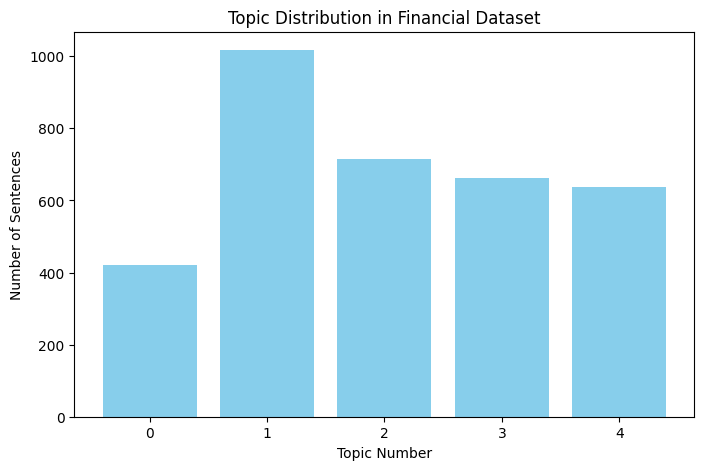

In [18]:
# Count sentences per topic
topic_counts = data['dominant_topic'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,5))
plt.bar(topic_counts.index, topic_counts.values, color='skyblue')
plt.xlabel('Topic Number')
plt.ylabel('Number of Sentences')
plt.title('Topic Distribution in Financial Dataset')
plt.xticks(topic_counts.index)
plt.show()


***• Briefly interpret each topic (e.g., “market movement”, “company performance”, etc.)***

| Topic | Keywords (Top 5)                             | Interpretation                      |
| ----- | -------------------------------------------- | ----------------------------------- |
| 0     | company, finland, helsinki, board, bank      | Company & General News / Governance |
| 1     | million, eur, share, net, sale               | Financial Performance / Earnings    |
| 2     | company, market, business, percent, customer | Market & Business Activity          |
| 3     | eur, mn, profit, operating, quarter          | Profit & Operational Metrics        |
| 4     | service, company, system, mobile, product    | Product / Service Announcements     |


# **Task 3: Sentiment Analysis Using Three Approaches**

# **A. FinBERT Sentiment Analysis**

***• Run FinBERT on your dataset***

In [19]:
# Import necessary packages
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix


i’ll use the pre-trained FinBERT model for financial sentiment:

In [33]:
#Load FinBERT
tokenizer = AutoTokenizer.from_pretrained("yiyanghkust/finbert-tone")
model = AutoModelForSequenceClassification.from_pretrained("yiyanghkust/finbert-tone")


config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/439M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/439M [00:00<?, ?B/s]

In [40]:
# Create a sentiment analysis pipeline
finbert_classifier = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

Device set to use cpu


In [41]:
# Apply FinBERT sentiment analysis to each original sentence
data['finbert_sentiment'] = data['sentence'].apply(lambda x: finbert_classifier(x)[0]['label'])

# Inspect the first 5 predictions
data[['sentence', 'sentiment', 'finbert_sentiment']].head()


,sentence,sentiment,finbert_sentiment
0,"According to Gran , the company has no plans t...",neutral,Neutral
1,With the new production plant the company woul...,positive,Positive
2,"For the last quarter of 2010 , Componenta 's n...",positive,Positive
3,"In the third quarter of 2010 , net sales incre...",positive,Positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive,Positive


***• Compute evaluation metrics:
o Accuracy
o Precision, Recall, F1
o Confusion Matrix***

In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert FinBERT predictions to lowercase for consistency
data['finbert_sentiment'] = data['finbert_sentiment'].str.lower()

# 1. Accuracy
accuracy = accuracy_score(data['sentiment'], data['finbert_sentiment'])
print(f"Accuracy: {accuracy:.4f}")

# 2. Precision, Recall, F1
report = classification_report(data['sentiment'], data['finbert_sentiment'], target_names=['negative', 'neutral', 'positive'])
print("Classification Report:\n", report)

# 3. Confusion Matrix
cm = confusion_matrix(data['sentiment'], data['finbert_sentiment'], labels=['negative', 'neutral', 'positive'])
print("Confusion Matrix:\n", cm)


Accuracy: 0.8772
Classification Report:
               precision    recall  f1-score   support

    negative       0.84      0.85      0.84       420
     neutral       0.88      0.96      0.92      2146
    positive       0.91      0.68      0.78       887

    accuracy                           0.88      3453
   macro avg       0.87      0.83      0.85      3453
weighted avg       0.88      0.88      0.87      3453

Confusion Matrix:
 [[ 357   53   10]
 [  27 2066   53]
 [  41  240  606]]


# **B. Local LLM Sentiment Analysis**

In [20]:
!pip install transformers sentencepiece accelerate --quiet

In [21]:
from transformers import AutoModelForCausalLM

***• Use any local or open-source LLM***

We need a small to medium model that can run in Colab without GPU memory issues.

For zero-shot sentiment analysis, Llama2-7B-chat (if using GPU) or MPT-7B-Instruct (lighter variant) works well.

Zero-shot means we give the model a prompt for sentiment classification directly without training.

In [ ]:
# Load tokenizer and model
model_name = "tiiuae/falcon-7b-instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16, device_map="auto")

# Create a text-generation pipeline
llm_pipeline = pipeline("text-generation", model=model, tokenizer=tokenizer, max_length=256)


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/9.95G [00:00<?, ?B/s]